This is the Titanic ML project from Kaggle where we are going to predict whether passengers survived or did not survive on the Titanic based on some info about them. We are given a train.csv and test.csv. It is a binary classification problem because they either survived or did not survive and only those 2 options

In [143]:
#imports 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, accuracy_score, roc_auc_score,f1_score, precision_recall_curve, roc_curve
from sklearn.tree import DecisionTreeClassifier


Reading in the data and looking at structure of the data

In [ ]:
data = pd.read_csv('C:/Users/stevi/Downloads/train.csv')
data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,433.000000,433.000000,433.000000,364.000000,433.000000,433.000000,433.000000
mean,439.757506,0.526559,1.824480,30.662308,0.965358,0.711316,56.902954
std,253.159139,0.499872,0.874882,16.616720,1.404754,1.014837,62.368464
min,2.000000,0.000000,1.000000,0.750000,0.000000,0.000000,15.045800
25%,225.000000,0.000000,1.000000,19.000000,0.000000,0.000000,26.000000
50%,447.000000,1.000000,2.000000,31.000000,1.000000,0.000000,31.275000
75%,646.000000,1.000000,3.000000,42.000000,1.000000,1.000000,69.550000
max,890.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [19]:
#Splitting into features and label
X = data.drop(labels=['PassengerId','Survived','Name','Ticket'], axis=1)
y = data['Survived']

Now lets find patterns and correlation throughout pre processing

In [20]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Sex       891 non-null    str    
 2   Age       714 non-null    float64
 3   SibSp     891 non-null    int64  
 4   Parch     891 non-null    int64  
 5   Fare      891 non-null    float64
 6   Cabin     204 non-null    str    
 7   Embarked  889 non-null    str    
dtypes: float64(2), int64(3), str(3)
memory usage: 55.8 KB


Going to drop Cabin because too many nulls, encoding sex and embarked, replacing na values in numeric with median, replacing str na with most frequent

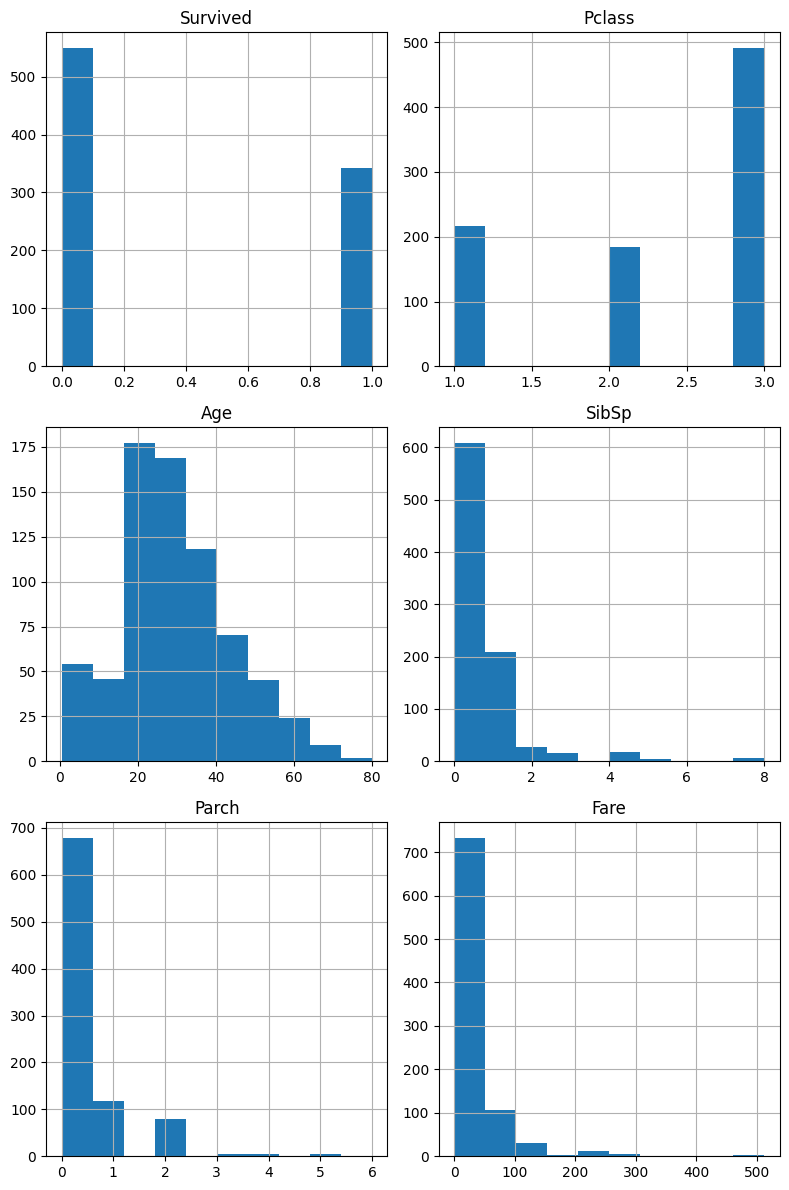

In [24]:
data.drop('PassengerId',axis=1).hist(bins=10, figsize=(8,12))
plt.tight_layout()
plt.show()


In [29]:
#checking to see which columns have the most correlation to Survived
corr_matrix = data.corr(numeric_only=True)
corr_matrix['Survived'].sort_values(ascending=False)

Survived       1.000000
Fare           0.257307
Parch          0.081629
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.077221
Pclass        -0.338481
Name: Survived, dtype: float64

[]

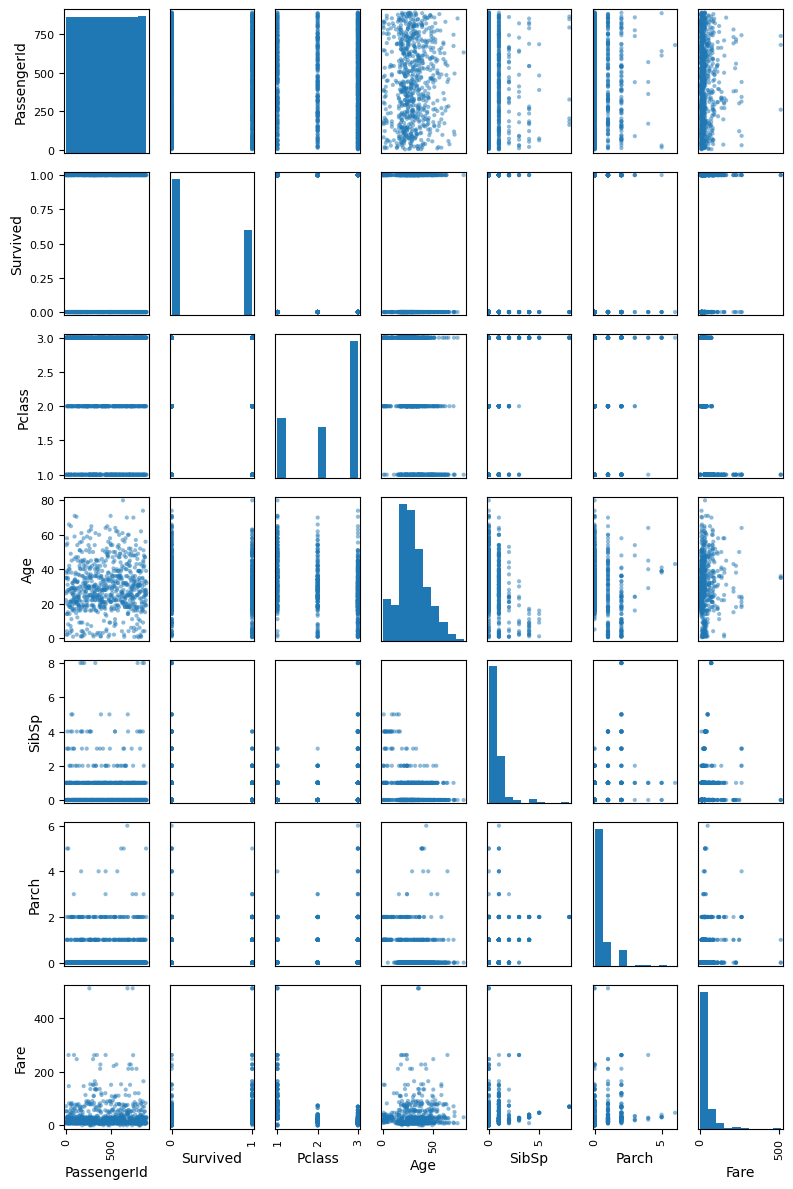

In [32]:
from pandas.plotting import scatter_matrix
scatter_matrix(data, figsize=(8,12))
plt.tight_layout()
plt.plot()

After looking at the correlations, I found as survival increased the Fare(price of ticket) increased, and the SibSp(number of siblings/parents) decreased along with age and the class by 0.33(suprising)

Now creating the pipelines to transform the data

In [64]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


In [65]:
cat_transformer = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder())
])#replaces na with most common and encodes to numerical vals
numeric_transformer = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])#replaces na with median from training and scales to a z score based on the mew and sigma of training data

pre_process = ColumnTransformer([
    ('numeric', numeric_transformer, ['Pclass','Age','SibSp','Parch','Fare']),
    ('cat', cat_transformer, ['Sex','Embarked'])
])


Going to create the model pipeline using logistic regression first

In [145]:
log_pip = Pipeline([
    ('transform', pre_process),
    ('predict', LogisticRegression())
])
forest_pip = Pipeline([
    ('transform', pre_process),
    ('predict', RandomForestClassifier(random_state=42))
])


In [86]:
#getting all the predictions from k-fold cross validation using 9 folds
predictions = cross_val_predict(log_pip, X=X, y=y, cv=9)


Looking at the accuracy of the predictions made using a confusion matrix because its a classifier

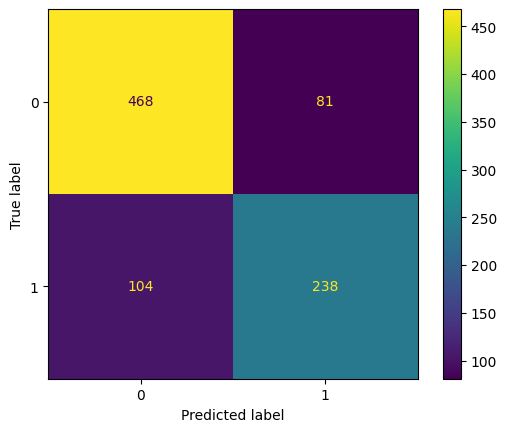

In [87]:

cm = confusion_matrix(y_true=y, y_pred=predictions)
ConfusionMatrixDisplay(cm).plot()
plt.show()

In [91]:
precision = precision_score(y_true=y, y_pred=predictions)
recall = recall_score(y_true=y, y_pred=predictions)
accuracy = accuracy_score(y_true=y, y_pred=predictions)
precision,recall, accuracy


(0.7460815047021944, 0.695906432748538, 0.792368125701459)

First run results off confusion matrix: 
Recall- 69.59%
Precision- 74.6%
accuracy- 79.2%
Now lets improve it through tuning

Lets get a bunch of threshold values by using each probability score as one 

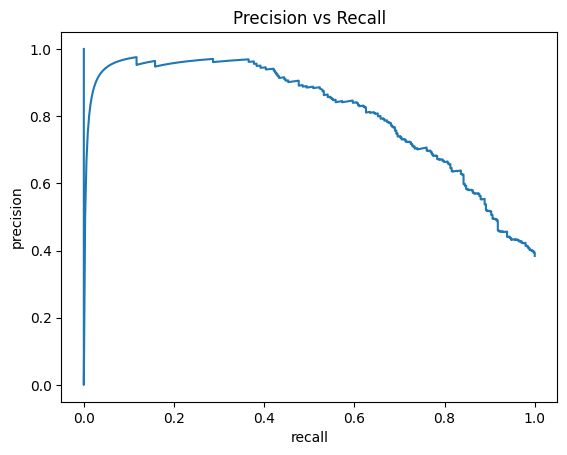

In [98]:
scores = cross_val_predict(log_pip, X, y, cv=9, method='decision_function')
precisions, recalls, thresholds = precision_recall_curve(y_true=y, y_score=scores)
plt.plot(recalls, precisions)
plt.title("Precision vs Recall")
plt.xlabel("recall")
plt.ylabel("precision")
plt.show()

In [110]:
ok_recall = (recalls[:-1] >= .75)
threshold = thresholds[ok_recall].max()
pred = (scores >= threshold).astype(int)

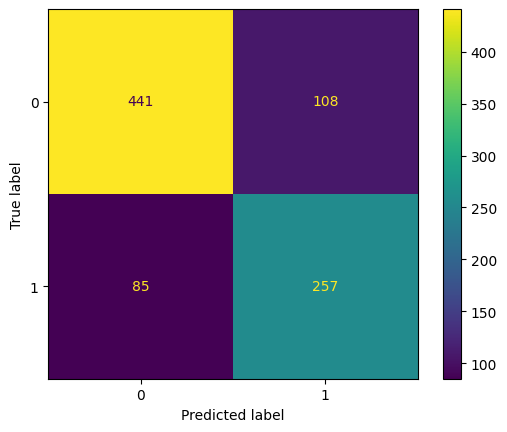

In [111]:
cm2 = confusion_matrix(y_true=y, y_pred=pred)
ConfusionMatrixDisplay(cm2).plot()
plt.show()

In [ ]:
prec2 = precision_score(y, pred)
rec2 = recall_score(y, pred)
acc2 = accuracy_score(y,pred)


(0.7041095890410959, 0.7514619883040936, 0.7833894500561167, 0.727015558698727)

Ended up getting the recall up to 75% with a precision of 70%, but I want to see if we can do better so im going to eval other models ROC curves to see better TPR values

In [146]:
lin_cv = cross_val_predict(log_pip, X, y, cv=8, method='decision_function')
forest_scores = cross_val_predict(forest_pip,X,y,cv=8,method='predict_proba')[:,1]

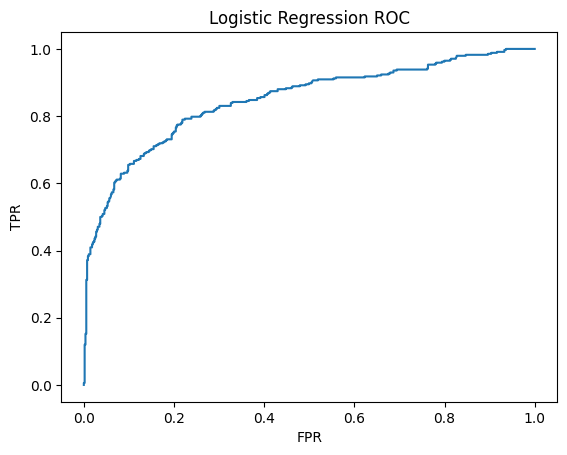

In [147]:
fpr,tpr,threshold1 = roc_curve(y,lin_cv)
fpr2,tpr2,thresh2 = roc_curve(y,forest_scores)
plt.plot(fpr,tpr)
plt.title("Logistic Regression ROC")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.show()

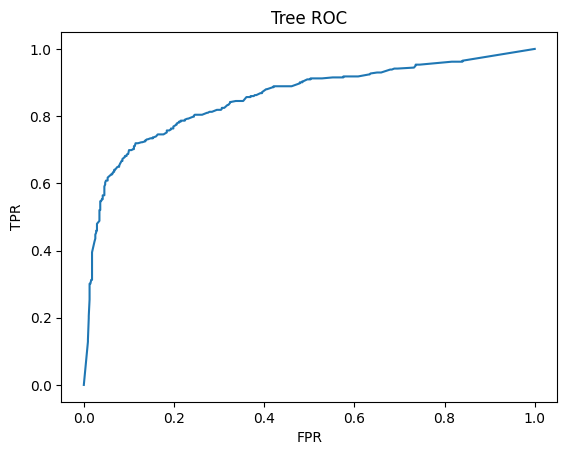

In [148]:
plt.plot(fpr2,tpr2)
plt.title("Tree ROC")
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.show()

Looking at the ROC curves I can see that the forest model seems to have a better recall (TPR) for the lower FPR, at around 0.80 seems to be promising

In [162]:
good_recall = (tpr2 >= 0.78)
thresh_2 = thresh2[good_recall].max()
pred2 = (forest_scores >= thresh_2).astype(int)




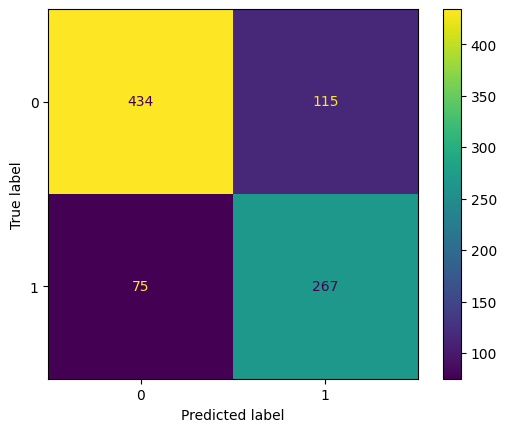

In [163]:
cm3 = confusion_matrix(y, pred2)
ConfusionMatrixDisplay(cm3).plot()
plt.show()

Found using the random forest classifier I could get the f1 score up to 73%

In [175]:
from sklearn.model_selection import FixedThresholdClassifier

final_model = FixedThresholdClassifier(forest_pip, threshold=thresh_2, response_method='predict_proba')
final_model.fit(X,y)

,"estimator estimator: estimator instanceThe binary classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...m_state=42))])
,"threshold threshold: {""auto""} or float, default=""auto""The decision threshold to use when converting posterior probability estimates(i.e. output of `predict_proba`) or decision scores (i.e. output of`decision_function`) into a class label. When `""auto""`, the threshold is setto 0.5 if `predict_proba` is used as `response_method`, otherwise it is set to0 (i.e. the default threshold for `decision_function`).",np.float64(0.35)
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'predict_proba'
,"pos_label pos_label: int, float, bool or str, default=NoneThe label of the positive class. Used to process the output of the`response_method` method. When `pos_label=None`, if `y_true` is in `{-1, 1}` or`{0, 1}`, `pos_label` is set to 1, otherwise an error will be raised.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The class labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimator instanceThe fitted classifier used when predicting.,Pipeline,Pipeline(step...m_state=42))])
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit.","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit.,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.No

Now time to test on the testing data

In [197]:
testX = pd.read_csv('c:\\Users\\stevi\\Downloads\\test.csv')
test_pred = final_model.predict(testX)
submission = pd.DataFrame({
    'PassengerId': testX['PassengerId'],
    'Survived': test_pred
})
submission.to_csv('titanic_submission.csv', index=False)
submission.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  418 non-null    int64
 1   Survived     418 non-null    int64
dtypes: int64(2)
memory usage: 6.7 KB
